In [ ]:
CATHERINE JOSEPH LWEHUMBIZA
BENG24COE_3
240242457000


TASK 3.1

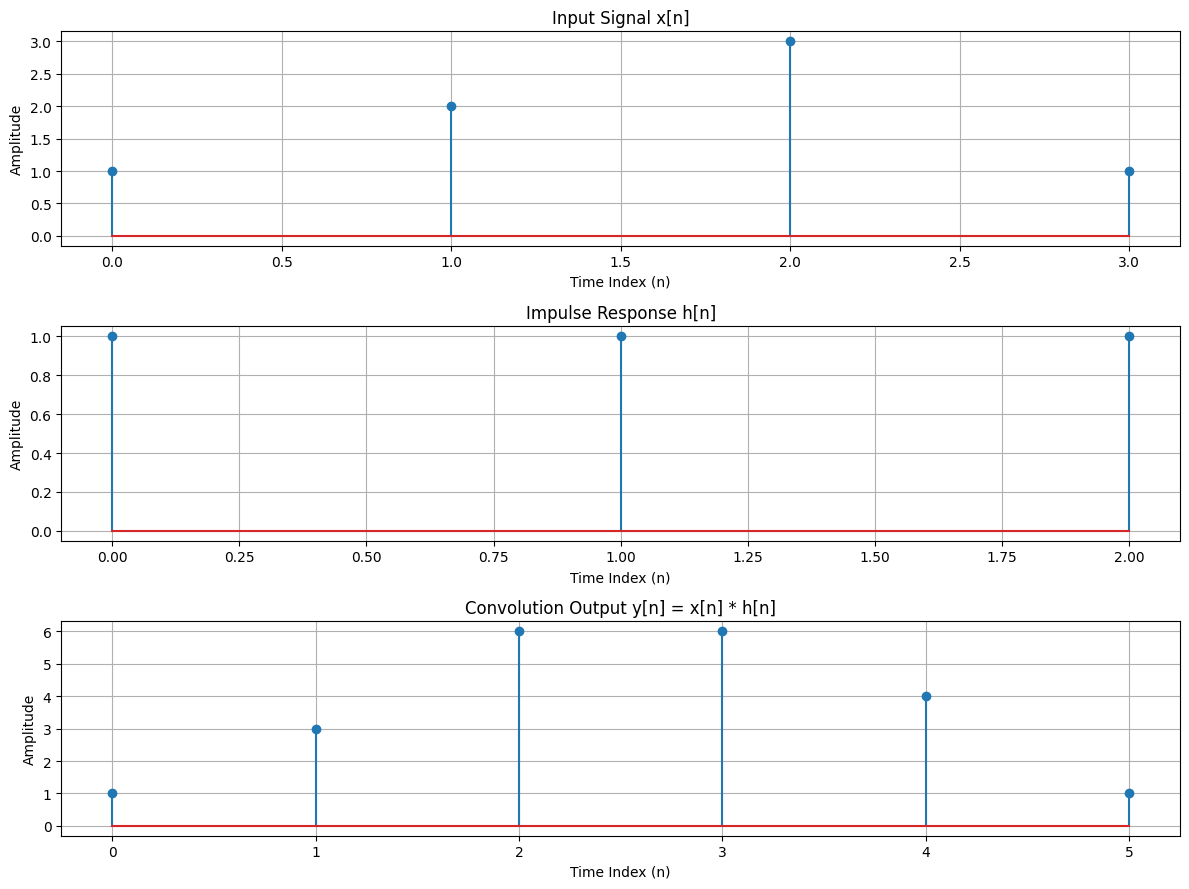

Convolution output: [1 3 6 6 4 1]


In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Input signals
x = np.array([1, 2, 3, 1])
h = np.array([1, 1, 1])

# Calculate convolution
y = np.convolve(x, h)

# Time indices
n_x = np.arange(len(x))
n_h = np.arange(len(h))
n_y = np.arange(len(y))

# Create three graphs
plt.figure(figsize=(12, 9))

# Graph 1: Input signal x[n]
plt.subplot(3, 1, 1)
plt.stem(n_x, x)
plt.title("Input Signal x[n]")
plt.xlabel("Time Index (n)")
plt.ylabel("Amplitude")
plt.grid(True)

# Graph 2: Impulse response h[n]
plt.subplot(3, 1, 2)
plt.stem(n_h, h)
plt.title("Impulse Response h[n]")
plt.xlabel("Time Index (n)")
plt.ylabel("Amplitude")
plt.grid(True)

# Graph 3: Convolution output y[n]
plt.subplot(3, 1, 3)
plt.stem(n_y, y)
plt.title("Convolution Output y[n] = x[n] * h[n]")
plt.xlabel("Time Index (n)")
plt.ylabel("Amplitude")
plt.grid(True)

plt.tight_layout()
plt.show()

# Display results
print("Convolution output:", y)

TASK 3.2

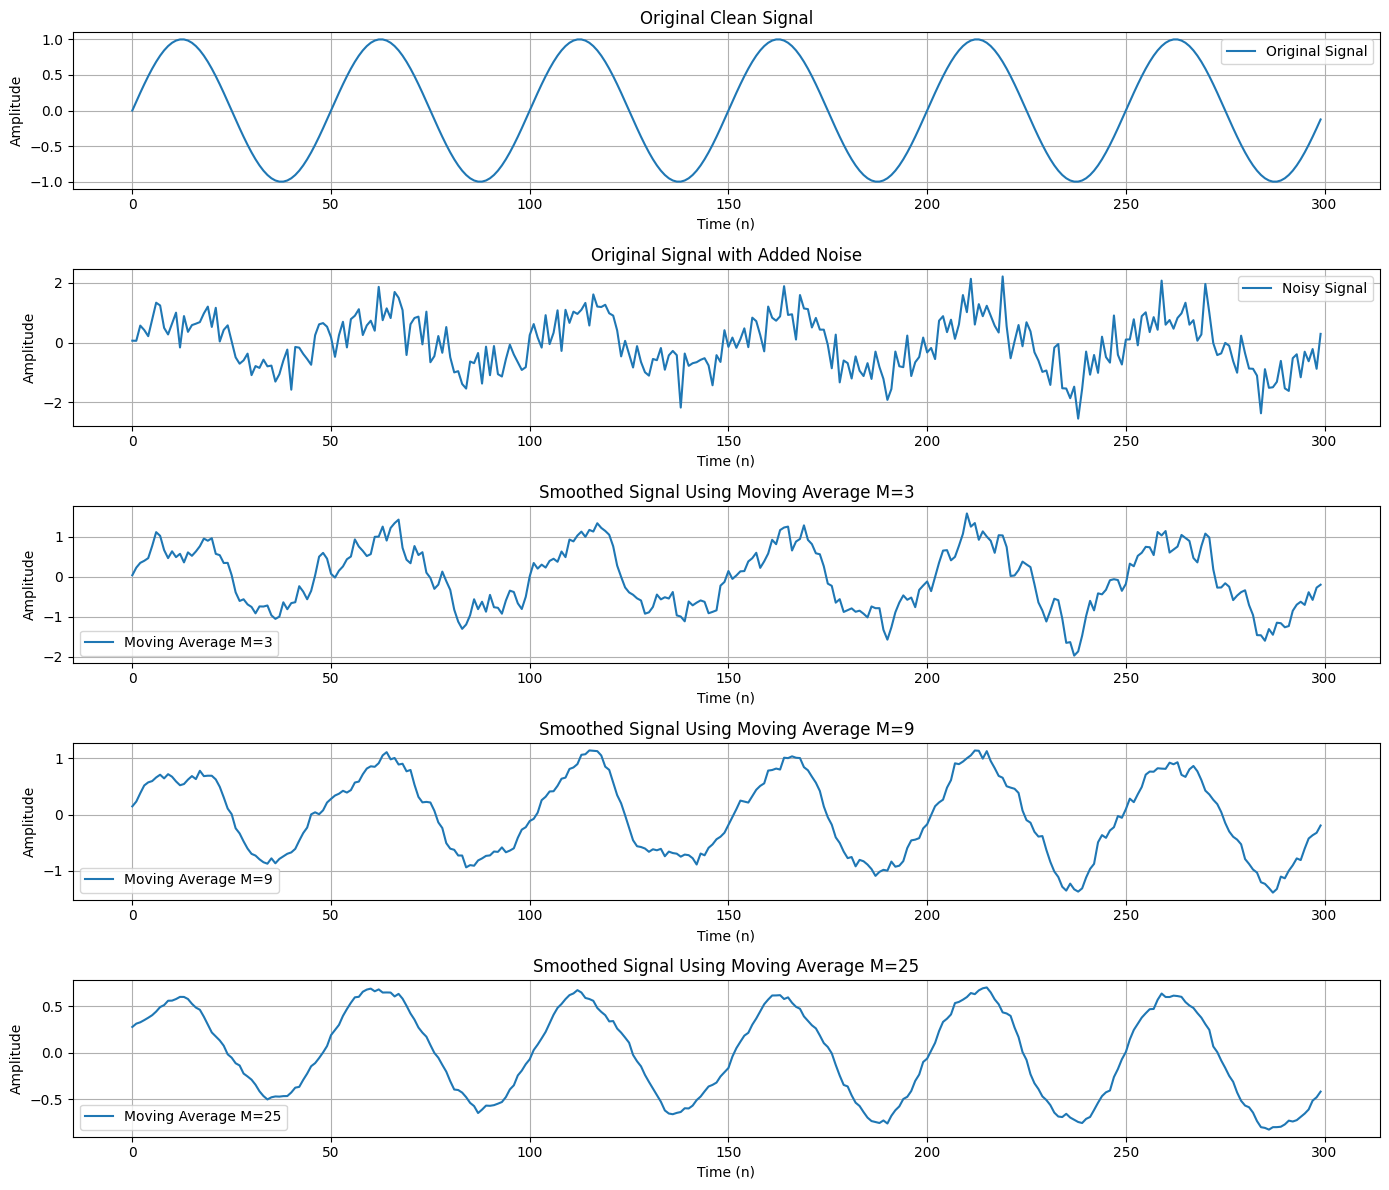

TASK 3.2 RESULTS
Moving Average M=3 completed successfully.
Moving Average M=9 completed successfully.
Moving Average M=25 completed successfully.
All signals have been plotted.


In [5]:

# WEEK 3 - TASK 3.2
# Smoothing a Noisy Signal Using Convolution

import numpy as np
import matplotlib.pyplot as plt

# Step 1: Generate the original signal
rng = np.random.default_rng(0)

n = np.arange(300)

original_signal = np.sin(2 * np.pi * n / 50)

# Step 2: Generate random noise
noise = 0.5 * rng.standard_normal(300)

# Step 3: Add noise to the original signal
noisy_signal = original_signal + noise

# Step 4: Apply moving average filters
M_values = [3, 9, 25]

filtered_signals = {}

for M in M_values:
    h = np.ones(M) / M
    filtered_signals[M] = np.convolve(noisy_signal, h, mode="same")

# Step 5: Plot all signals
plt.figure(figsize=(14, 12))

plt.subplot(5, 1, 1)
plt.plot(n, original_signal, label="Original Signal")
plt.title("Original Clean Signal")
plt.xlabel("Time (n)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.legend()

plt.subplot(5, 1, 2)
plt.plot(n, noisy_signal, label="Noisy Signal")
plt.title("Original Signal with Added Noise")
plt.xlabel("Time (n)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.legend()

for i, M in enumerate(M_values):
    plt.subplot(5, 1, i + 3)
    plt.plot(n, filtered_signals[M],
             label=f"Moving Average M={M}")
    plt.title(f"Smoothed Signal Using Moving Average M={M}")
    plt.xlabel("Time (n)")
    plt.ylabel("Amplitude")
    plt.grid(True)
    plt.legend()

plt.tight_layout()
plt.show()

# Step 6: Display noise reduction results
print("TASK 3.2 RESULTS")

for M in M_values:
    print(f"Moving Average M={M} completed successfully.")

print("All signals have been plotted.")


TASK 3.3

x^2             Linear=False, Time-Invariant=True
n*x(n)          Linear=True, Time-Invariant=False
Moving Average  Linear=True, Time-Invariant=True


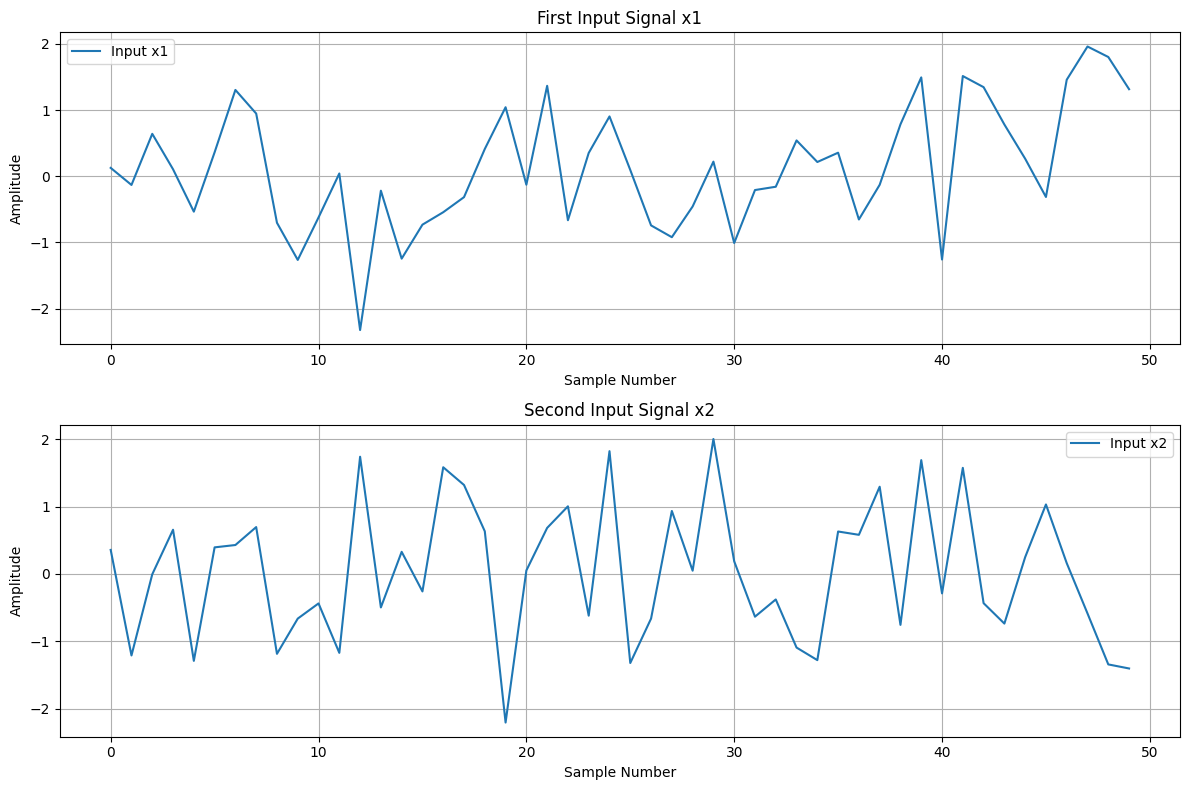

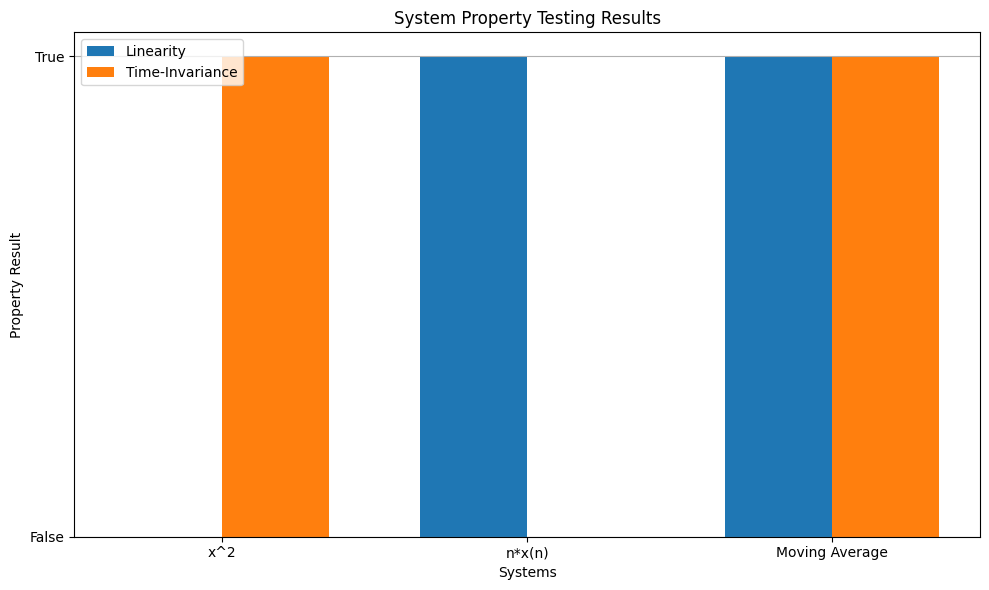

In [6]:

# WEEK 3 - TASK 3.3
# Testing Linearity and Time-Invariance

import numpy as np
import matplotlib.pyplot as plt

# Step 1: Generate two input signals
rng = np.random.default_rng(0)

x1 = rng.standard_normal(50)
x2 = rng.standard_normal(50)

# Step 2: Define constants
a = 2.0
b = -3.0

# Step 3: Define three systems
systems = {
    "x^2": lambda x: x**2,
    "n*x(n)": lambda x: np.arange(len(x)) * x,
    "Moving Average": lambda x: np.convolve(x, np.ones(3)/3)[:len(x)]
}

# Step 4: Test linearity and time-invariance
results = {}

for name, T in systems.items():

    # Test linearity
    linear = np.allclose(
        T(a*x1 + b*x2),
        a*T(x1) + b*T(x2)
    )

    # Create delayed input
    xd = np.concatenate([np.zeros(5), x1])[:50]

    # Apply system to delayed input
    output_delayed_input = T(xd)

    # Delay original output
    original_output = T(x1)
    delayed_output = np.concatenate(
        [np.zeros(5), original_output]
    )[:50]

    # Test time-invariance
    time_invariant = np.allclose(
        output_delayed_input,
        delayed_output
    )

    results[name] = (linear, time_invariant)

    print(f"{name:15s} Linear={linear}, Time-Invariant={time_invariant}")


# Step 5: Plot input signals
plt.figure(figsize=(12, 8))

plt.subplot(2, 1, 1)
plt.plot(x1, label="Input x1")
plt.title("First Input Signal x1")
plt.xlabel("Sample Number")
plt.ylabel("Amplitude")
plt.grid(True)
plt.legend()

plt.subplot(2, 1, 2)
plt.plot(x2, label="Input x2")
plt.title("Second Input Signal x2")
plt.xlabel("Sample Number")
plt.ylabel("Amplitude")
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()


# Step 6: Display results in a graph
systems_names = list(results.keys())
linearity_values = [int(results[name][0]) for name in systems_names]
time_values = [int(results[name][1]) for name in systems_names]

positions = np.arange(len(systems_names))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(positions - width/2, linearity_values,
        width, label="Linearity")

plt.bar(positions + width/2, time_values,
        width, label="Time-Invariance")

plt.xticks(positions, systems_names)
plt.yticks([0, 1], ["False", "True"])
plt.title("System Property Testing Results")
plt.xlabel("Systems")
plt.ylabel("Property Result")
plt.legend()
plt.grid(axis="y")

plt.tight_layout()
plt.show()


TASK 3.4

TRUE DELAY: 37 samples
ESTIMATED DELAY: 37 samples


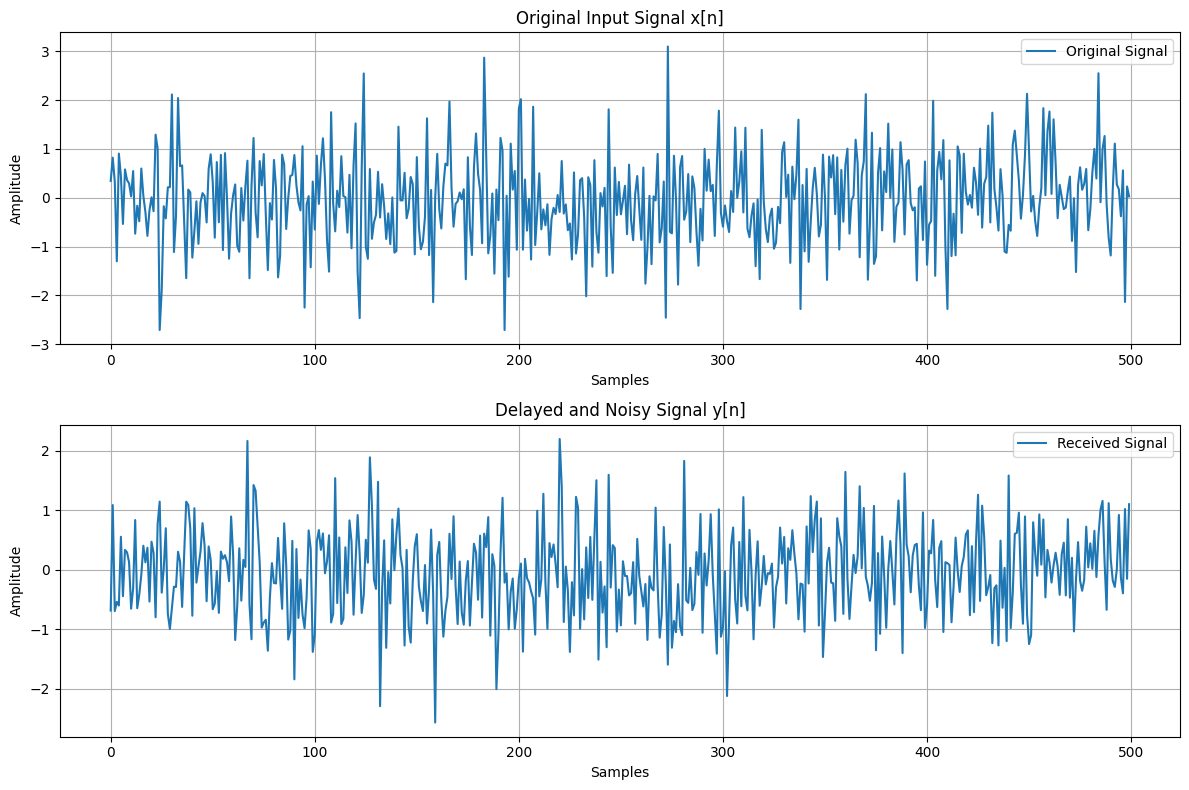

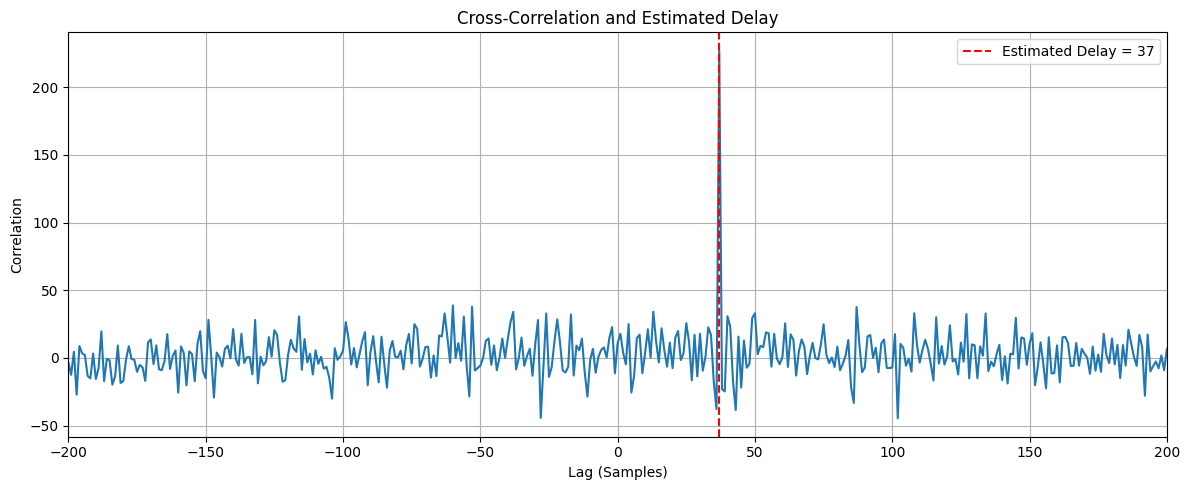


NOISE LEVEL TESTING
Noise level = 0.5: Estimated delay = 37 samples
Noise level = 1: Estimated delay = 37 samples
Noise level = 2: Estimated delay = 37 samples
Noise level = 4: Estimated delay = 37 samples

SOUND DISTANCE CALCULATION
Delay in seconds: 0.037
Distance: 12.690999999999999 meters


In [7]:

# WEEK 3 - TASK 3.4
# Finding Hidden Delay Using Cross-Correlation

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Step 1: Generate a random input signal
rng = np.random.default_rng(1)

fs = 1000
x = rng.standard_normal(500)

# Step 2: Introduce a delay
true_delay = 37

delayed_signal = np.concatenate([
    np.zeros(true_delay),
    0.6 * x
])[:500]

# Step 3: Add noise to received signal
noise = 0.5 * rng.standard_normal(500)

y = delayed_signal + noise

# Step 4: Calculate cross-correlation
r = signal.correlate(y, x, mode="full")

# Step 5: Calculate lag values
lags = signal.correlation_lags(
    len(y), len(x), mode="full"
)

# Step 6: Estimate delay
estimated_delay = lags[np.argmax(r)]

print("TRUE DELAY:", true_delay, "samples")
print("ESTIMATED DELAY:", estimated_delay, "samples")

# Step 7: Plot input and received signals
plt.figure(figsize=(12, 8))

plt.subplot(2, 1, 1)
plt.plot(x, label="Original Signal")
plt.title("Original Input Signal x[n]")
plt.xlabel("Samples")
plt.ylabel("Amplitude")
plt.grid(True)
plt.legend()

plt.subplot(2, 1, 2)
plt.plot(y, label="Received Signal")
plt.title("Delayed and Noisy Signal y[n]")
plt.xlabel("Samples")
plt.ylabel("Amplitude")
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

# Step 8: Plot cross-correlation
plt.figure(figsize=(12, 5))

plt.plot(lags, r)
plt.axvline(
    estimated_delay,
    color="red",
    linestyle="--",
    label=f"Estimated Delay = {estimated_delay}"
)

plt.title("Cross-Correlation and Estimated Delay")
plt.xlabel("Lag (Samples)")
plt.ylabel("Correlation")
plt.xlim(-200, 200)
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

# Step 9: Test the effect of different noise levels
noise_levels = [0.5, 1, 2, 4]

print("\nNOISE LEVEL TESTING")

for noise_level in noise_levels:

    test_noise = noise_level * rng.standard_normal(500)

    test_y = delayed_signal + test_noise

    test_r = signal.correlate(
        test_y, x, mode="full"
    )

    test_delay = lags[np.argmax(test_r)]

    print(
        f"Noise level = {noise_level}: "
        f"Estimated delay = {test_delay} samples"
    )

# Step 10: Calculate distance travelled by sound
delay_seconds = estimated_delay / fs

speed_of_sound = 343

distance = speed_of_sound * delay_seconds

print("\nSOUND DISTANCE CALCULATION")
print("Delay in seconds:", delay_seconds)
print("Distance:", distance, "meters")


TASK 3.5

IMPULSE RESPONSE USING DIRECT RECURSION
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]

IMPULSE RESPONSE USING LFILTER
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]

THEORETICAL IMPULSE RESPONSE
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]

COMPARISON RESULTS
Direct recursion and lfilter: True
lfilter and theoretical response: True


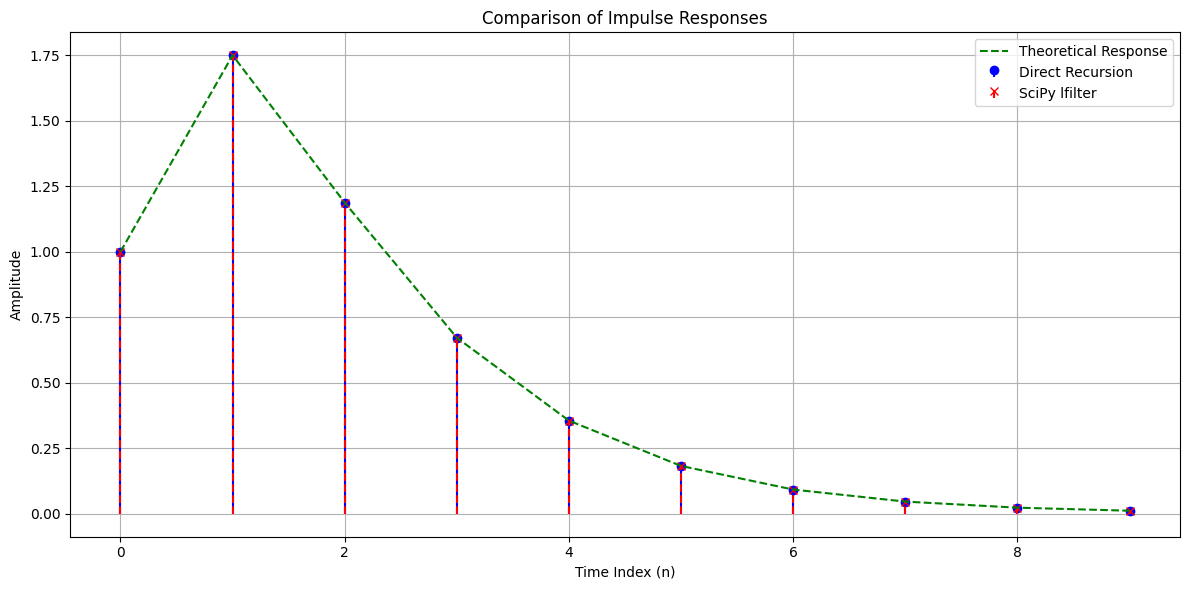


STEP RESPONSE
[1.         2.75       3.9375     4.609375   4.96484375 5.14746094
 5.23999023 5.28656006 5.30992126 5.32162094 5.32747555 5.33040404
 5.33186859 5.33260094 5.33296713 5.33315023 5.33324178 5.33328756
 5.33331045 5.33332189 5.33332761 5.33333047 5.3333319  5.33333262
 5.33333298 5.33333315 5.33333324 5.33333329 5.33333331 5.33333332
 5.33333333 5.33333333 5.33333333 5.33333333 5.33333333 5.33333333
 5.33333333 5.33333333 5.33333333 5.33333333 5.33333333 5.33333333
 5.33333333 5.33333333 5.33333333 5.33333333 5.33333333 5.33333333
 5.33333333 5.33333333]

FINAL VALUE CALCULATION
H(1) = 5.333333333333333
Final step response value = 5.333333333333323


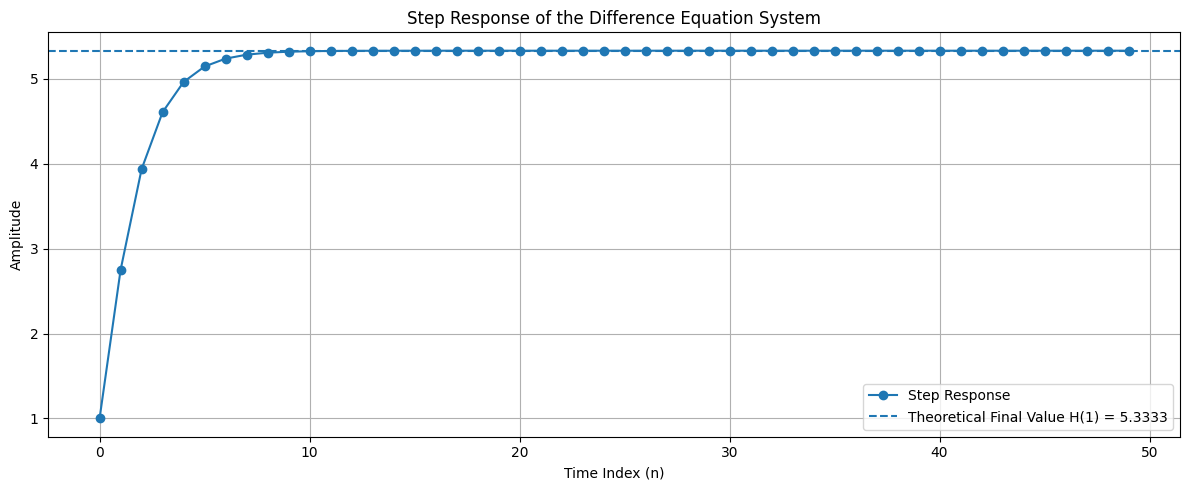


SYSTEM STABILITY
Sum of absolute impulse response: 5.321620941162109
The impulse response decays with time,
therefore the system is stable.


In [8]:

# WEEK 3 - TASK 3.5
# Solving Difference Equations

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Step 1: Define the system coefficients
b = [1, 1]
a = [1, -0.75, 0.125]

# Step 2: Create an impulse signal
N = 10

impulse = np.zeros(N)
impulse[0] = 1

# Step 3: Solve using direct recursion
h = np.zeros(N)

for n in range(N):

    x_n = impulse[n]

    x_previous = impulse[n-1] if n >= 1 else 0

    y_previous = h[n-1] if n >= 1 else 0

    y_previous2 = h[n-2] if n >= 2 else 0

    h[n] = (
        x_n + x_previous
        + 0.75*y_previous
        - 0.125*y_previous2
    )

print("IMPULSE RESPONSE USING DIRECT RECURSION")
print(h)


# Step 4: Solve using scipy.signal.lfilter()
h_filter = signal.lfilter(b, a, impulse)

print("\nIMPULSE RESPONSE USING LFILTER")
print(h_filter)


# Step 5: Calculate theoretical impulse response
n = np.arange(N)

h_theory = 6*(0.5**n) - 5*(0.25**n)

print("\nTHEORETICAL IMPULSE RESPONSE")
print(h_theory)


# Step 6: Compare the three results
print("\nCOMPARISON RESULTS")

print("Direct recursion and lfilter:",
      np.allclose(h, h_filter))

print("lfilter and theoretical response:",
      np.allclose(h_filter, h_theory))


# Step 7: Plot impulse responses
plt.figure(figsize=(12, 6))

plt.stem(n, h, linefmt='b-', markerfmt='bo',
         basefmt=' ', label="Direct Recursion")

plt.stem(n, h_filter, linefmt='r--', markerfmt='rx',
         basefmt=' ', label="SciPy lfilter")

plt.plot(n, h_theory, 'g--',
         label="Theoretical Response")

plt.title("Comparison of Impulse Responses")
plt.xlabel("Time Index (n)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# Step 8: Calculate the step response
step = np.ones(50)

step_response = signal.lfilter(b, a, step)

print("\nSTEP RESPONSE")
print(step_response)


# Step 9: Calculate theoretical final value H(1)
H1 = sum(b) / sum(a)

print("\nFINAL VALUE CALCULATION")
print("H(1) =", H1)
print("Final step response value =", step_response[-1])


# Step 10: Plot step response
plt.figure(figsize=(12, 5))

plt.plot(step_response, marker='o',
         label="Step Response")

plt.axhline(H1, linestyle='--',
            label=f"Theoretical Final Value H(1) = {H1:.4f}")

plt.title("Step Response of the Difference Equation System")
plt.xlabel("Time Index (n)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# Step 11: Determine system stability
print("\nSYSTEM STABILITY")
print("Sum of absolute impulse response:",
      np.sum(np.abs(h_filter)))

print("The impulse response decays with time,")
print("therefore the system is stable.")


# WEEK 3: ANALYSIS QUESTIONS AND ANSWERS

## Question 1: Why is np.convolve() faster than the convolution function implemented using Python loops? Estimate the number of multiplications required for two sequences of length 2000.

**Answer:**

The `np.convolve()` function is faster because it uses an optimized implementation written in compiled code, while the manually implemented convolution function uses Python nested loops. Python loops require more execution time because each iteration is handled by the Python interpreter.

For two sequences of length 2000, the approximate number of multiplications is calculated as:

Number of multiplications = L × M

= 2000 × 2000

= 4,000,000 multiplications.

Therefore, approximately four million multiplications are required to perform the convolution of the two sequences.

## Question 2: Which of the systems tested in Task 3.3 are linear and time-invariant? Can these properties be predicted from the system definitions?

**Answer:**

The experiment tested three different systems: the square system, the time-dependent system and the moving average system.

1. **Square system, T(x) = x²:** This system is nonlinear because it does not satisfy the superposition principle. However, it is time-invariant because delaying the input produces an equally delayed output.

2. **Time-dependent system, T(x) = nx(n):** This system is linear because it satisfies the superposition principle. However, it is time-varying because its output depends on the time index n.

3. **Moving Average System:** This system is both linear and time-invariant because it satisfies the superposition principle and produces the same output pattern when the input is delayed.

These properties can be predicted mathematically from the system definitions by applying the conditions of linearity and time-invariance.

## Question 3: Give two engineering applications of cross-correlation in Tanzania.

**Answer:**

Cross-correlation has several engineering applications in Tanzania. Two important examples are:

1. **Water Pipeline Leak Detection:** Water authorities can use sensors installed along water pipelines to detect unusual sound signals caused by water leakage. Cross-correlation helps estimate the time difference between signals received by different sensors. This information can help engineers locate the position of a leak.

2. **GPS Navigation and Positioning:** GPS receivers used in vehicles, mobile phones and surveying equipment compare received satellite signals with locally generated reference codes. Cross-correlation helps determine signal timing and estimate the distance between satellites and receivers. This supports accurate positioning and navigation.

## Question 4: Is the system in Task 3.5 FIR or IIR? Is it stable? Explain your answer.

**Answer:**

The system in Task 3.5 is an Infinite Impulse Response (IIR) system because its difference equation contains previous output values, such as y(n-1) and y(n-2). This causes the impulse response to continue for an indefinite number of samples, although its amplitude decreases with time.

The system is stable because its impulse response decays exponentially and is absolutely summable. This means that a bounded input produces a bounded output.

Therefore, the system is classified as a stable IIR system.

---

# AI USE STATEMENT

Artificial Intelligence (AI) was used as a learning assistant during this laboratory assignment. It helped in understanding convolution, correlation, linearity, time-invariance and difference equations. AI assistance was also used to explain Python programming code, identify programming errors, interpret graphs and understand experimental results. All practical tasks were implemented and executed using Google Colab, and the results were reviewed before being included in the laboratory report.

